# Build Forcing Validation - Precipitation
This is a comparison between NLDAS precipitation at Tony Grove and snotel. There is no GAMUT precip data.

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
#from gdriver.gdriver import get_credentials, getCSVtoPandas
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20150101'
end_date = '20150301'
buildforcing_version = 'v0.1.0'
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

### Load Datasets

In [3]:
nldas_forcing = xr.open_dataset(os.path.join(environment,'nldas',f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [ ]:
nldas_forcing

In [4]:
# Extract the precipitation data from nldas
nldas_precip = nldas_forcing['Rainf'].to_dataframe()

# Localize the precip data to UTC and then change to America/Denver
nldas_precip.index = nldas_precip.index.tz_localize('UTC').tz_convert('America/Denver')

# Resample to daily
nldas_precip_daily = nldas_precip.resample('D').sum()

In [5]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [ ]:
snotel.data.head()

In [6]:
# Load the forcing dataset
sitename = site.replace(' ', '').lower()
tg_forcing = xr.open_dataset(os.path.join(environment,'forcing',f'{sitename}_{start_date}_{end_date}_{buildforcing_version}.nc'))

In [ ]:
tg_forcing

In [7]:
# Extract Tair from dataset to a pandas dataframe ignoring the lat/lon dimensions
# and keeping the time dimension
forcing_precip = tg_forcing['Rainf'].isel(latitude=0, longitude=0).to_dataframe()
forcing_precip.index = forcing_precip.index.tz_localize('UTC').tz_convert('America/Denver')

# Convert forcing to hourly total by multiplying by 3600 seconds
forcing_precip['Rainf'] = forcing_precip['Rainf'] * 3600

In [9]:
# Resample to daily
forcing_precip_daily = forcing_precip.resample('D').sum()

### Plots

<Axes: xlabel='time'>

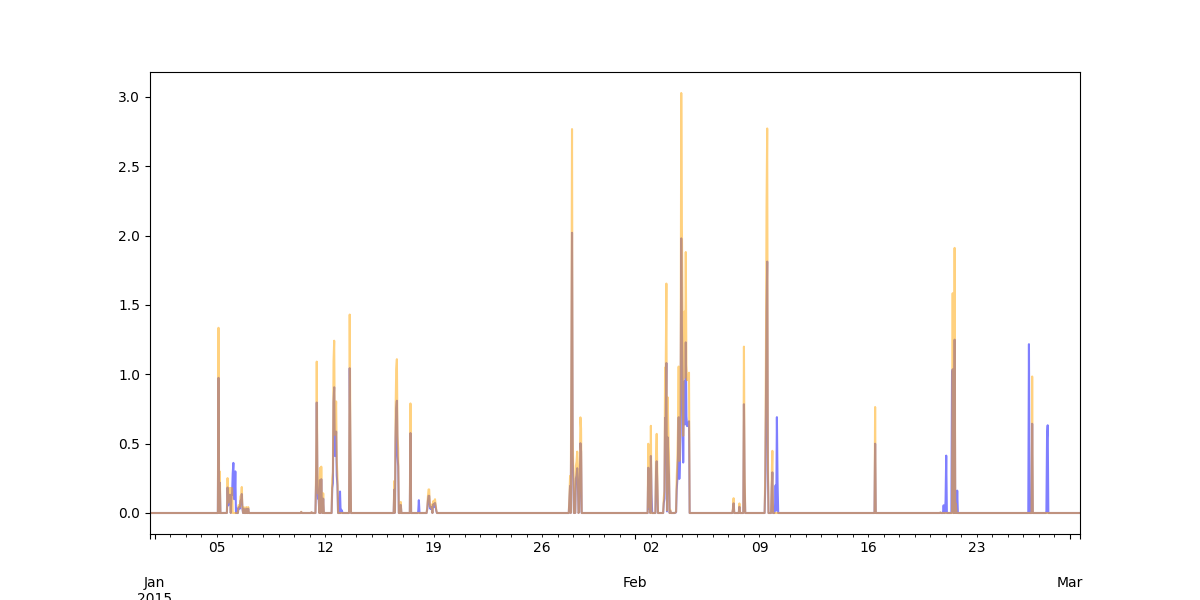

In [8]:
# Plot NLDAS and forcing precip data
fig, ax = plt.subplots(figsize=(12, 6))
nldas_precip['Rainf'].plot(ax=ax, label='NLDAS Precip', color='blue', alpha=0.5)
forcing_precip['Rainf'].plot(ax=ax, label='Forcing Precip', color='orange', alpha=0.5)

<Axes: xlabel='Date&Time'>

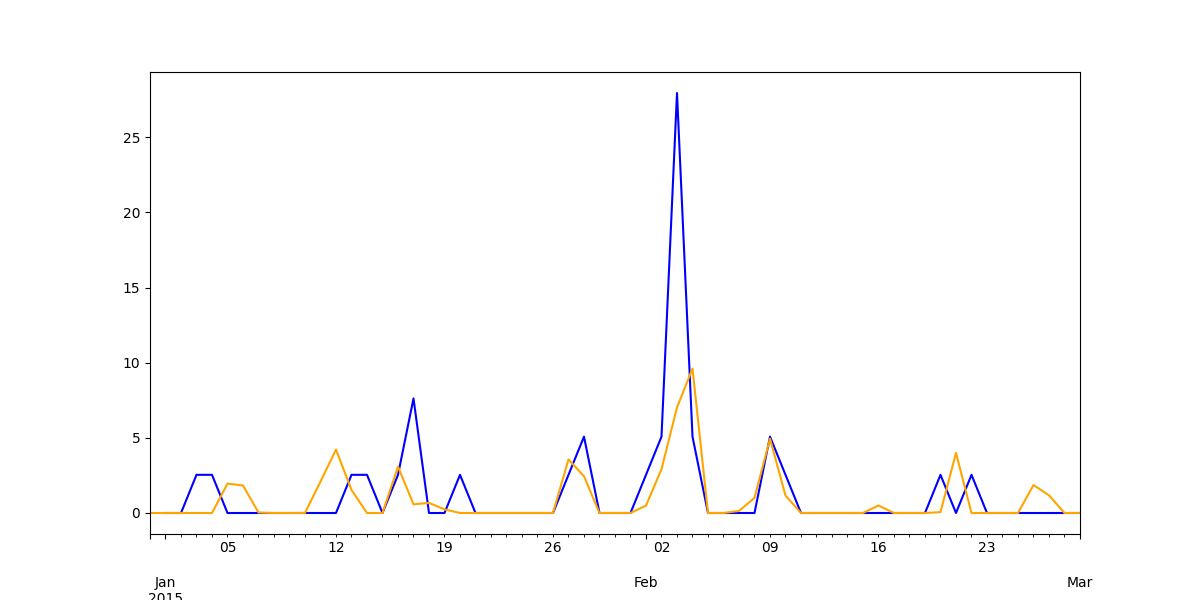

In [10]:
# Plot SNOTEL and NLDAS data
fig, ax = plt.subplots(figsize=(12, 6))
snotel.data.loc[start_date:end_date,'precip_mm'].plot(ax=ax, label='SNOTEL Precipitation', color='blue')
nldas_precip_daily['Rainf'].plot(ax=ax, label='NLDAS Precipitation', color='orange')

- Even when both datasets are daily there is a significant difference in the timing of events.
- Even weekly is going to be problematic.

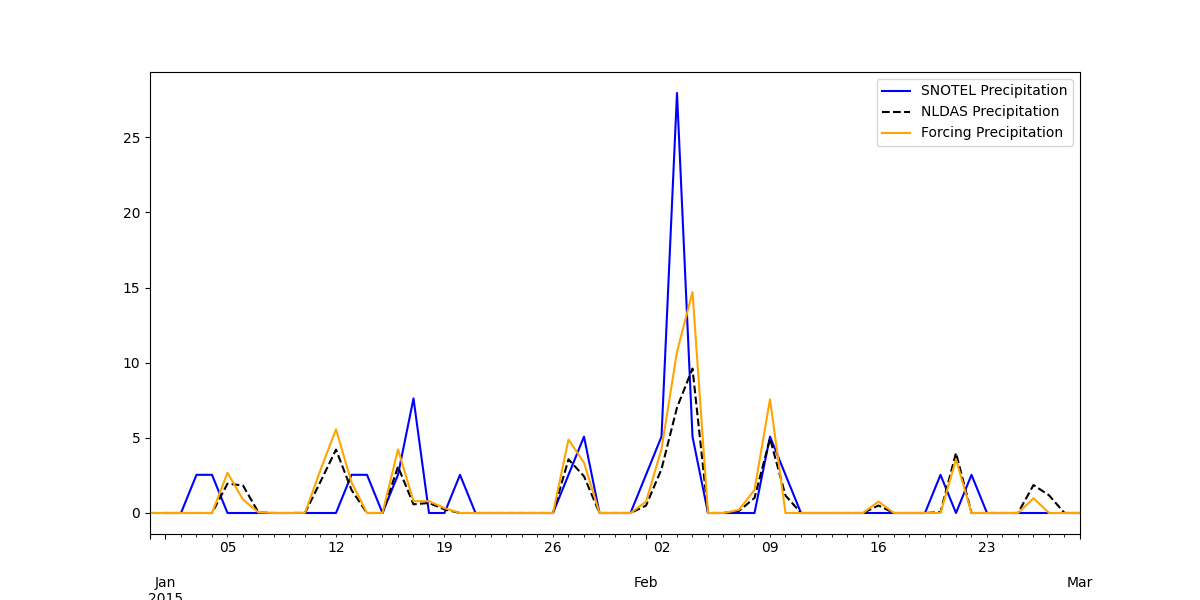

In [13]:
# Plot SNOTEL and Forcing data
fig, ax = plt.subplots(figsize=(12, 6))
snotel.data.loc[start_date:end_date,'precip_mm'].plot(ax=ax, label='SNOTEL Precipitation', color='blue')
nldas_precip_daily['Rainf'].plot(ax=ax, label='NLDAS Precipitation', style='--k')
forcing_precip_daily['Rainf'].plot(ax=ax, label='Forcing Precipitation', color='orange')
ax.legend()